# EmbeddingGemma2: lower capacity + loss curves (are we overfitting?)

Every EG2 checkpoint so far looks fine on L1/L2 but collapses to NOISE on other recordings (aggression keeps 34% of windows with noiseaug_hr, small_v2 keeps 64%).
More training made it worse (extended / decoder checkpoints), and the old notebooks had **no validation split**, so we never saw a loss curve.

This notebook trains several capacity settings **from the base model** (not continued from an older checkpoint), on the same data and the same noise augmentation as noiseaug_hr, and logs train **and** held-out curves every epoch:

| run | LoRA | layers | modules | other |
|---|---|---|---|---|
| `r16_full` | r=16 | all | q,k,v,o | the noiseaug_hr setting, as a reference |
| `r4_qv` | r=4 | all | q,v | more dropout, weight decay 0.05, lower encoder LR, small decoder |
| `r4_qv_top4` | r=4 | last 4 | q,v | same as `r4_qv` |
| `frozen` | none trained | – | – | linear heads on the frozen tower (floor) |

**Validation split:** L1 and the L2+noise file are stitched 5120-sample windows, and neighbours come from the same call / the same stretch of noise. A random window split would leak, so whole blocks of `BLOCK_WINDOWS` consecutive windows go to validation.

**Out-of-domain monitor (optional but the most important curve):** put a few aggression wavs in `AGGR_DIR`. Each epoch logs the share of aggression windows predicted NOISE. If that rises while L1/L2 validation stays flat, the model is fitting the training recordings.

**What overfitting looks like here:** validation classification loss turns up while train keeps falling (growing generalization gap), or the aggression NOISE % climbs over epochs. Each run keeps the checkpoint from its best validation epoch (early stopping).

In [1]:
!pip install -U torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 101.2 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [2]:
import os, re, copy, glob, json, inspect, shutil, time
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchaudio
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from transformers import AutoConfig, AutoModel, AutoFeatureExtractor
from peft import LoraConfig, get_peft_model

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

W1110 10:40:19.008000 409 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1110 10:40:19.049000 409 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Mounted at /content/drive


## Settings
`RUNS` holds only what differs from `BASE_RUN`. Put the run names you want in `RUNS_TO_TRAIN` (each run is one full training, so start with two if GPU time is tight: `r16_full` and `r4_qv_top4`).

In [3]:
DATA      = '/content/drive/MyDrive/dolphin data'
AUDIO_L1  = f'{DATA}/l1.wav'
LABELS_L1 = f'{DATA}/l1.csv'
AUDIO_L2  = f'{DATA}/l1_extended_from_l2_noise.wav'      # L2 calls (pseudo-labelled call type) + naive_noise windows
LABELS_L2 = f'{DATA}/l1_extended_from_l2_noise.csv'
AGGR_DIR  = f'{DATA}/aggression'                          # optional: a few aggression wavs (out-of-domain monitor only, never trained on)
OUT_ROOT  = '/content/drive/MyDrive/dolphin'

MID         = "google/embeddinggemma-2"
SR          = 16_000          # rate the feature extractor is told; samples go in unchanged (same as all previous checkpoints)
WIN         = 5120
NUM_CLASSES = 5
PROJ_DIM    = 128
LABEL_MAP   = {2: 'WSTL_DOWN', 1: 'WSTL_UP', 4: 'BURST', 3: 'ECHO', 0: 'NOISE'}
reverse     = {v: k for k, v in LABEL_MAP.items()}
all_labels  = set(reverse.keys())

# ---- split / training loop ----
SEED          = 0
VAL_FRAC      = 0.15          # share of blocks held out
BLOCK_WINDOWS = 50            # consecutive windows per block (50 * 5120 samples ~ 5.8 s at 44.1 kHz)
BATCH_SIZE    = 100
MAX_EPOCHS    = 20
PATIENCE      = 4             # stop after this many epochs without a better SELECT_ON
SELECT_ON     = 'val_cls'     # early-stopping metric (lower is better)
STEPS_PER_EPOCH = None        # cap optimizer steps per epoch (None = full balanced epoch); lower = more frequent val/checkpoints
VAL_MAX       = 1500          # validation triplets (class balanced)
PROBE_N       = 300           # windows per NOISE-rate probe
AGGR_N        = 400           # aggression windows in the out-of-domain monitor

# ---- background-noise augmentation (same as noiseaug_hr) ----
P_AUG, R_MIN, R_MAX = 0.5, 0.25, 4.0

BASE_RUN = dict(
    lora_r=16, lora_alpha=32, lora_dropout=0.05,
    lora_modules=('q_proj', 'k_proj', 'v_proj', 'o_proj'),
    lora_last_n=None,         # None = every layer, k = only the last k layers
    train_encoder=True,
    head_dropout=0.1, weight_decay=0.01,
    lr_enc=2e-4, lr_head=1e-3,
    decoder='large', recon_w=1.0, triplet_w=0.5, margin=0.3,
)
LOW = dict(lora_r=4, lora_alpha=8, lora_dropout=0.1, lora_modules=('q_proj', 'v_proj'),
           head_dropout=0.3, weight_decay=0.05, lr_enc=1e-4, decoder='small', recon_w=0.5)
RUNS = {
    'r16_full':   {},
    'r4_qv':      dict(LOW),
    'r4_qv_top4': dict(LOW, lora_last_n=4),
    'frozen':     dict(LOW, train_encoder=False),
}
RUNS_TO_TRAIN = ['r16_full', 'r4_qv', 'r4_qv_top4', 'frozen']

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# bf16 autocast on Ampere+ (A100 / L4); T4 has no bf16 and stays fp32 -> pick an A100/L4 runtime
AMP_DTYPE = torch.bfloat16 if DEVICE == "cuda" and torch.cuda.is_bf16_supported() else None
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
def amp():
    return torch.autocast("cuda", dtype=AMP_DTYPE or torch.float32, enabled=AMP_DTYPE is not None)
print(DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "", "amp:", AMP_DTYPE)

cuda Tesla T4 amp: torch.bfloat16


## Model
Same `WDPModel` as before (one encoder pass for anchor, positive and negative; mean pool → 128-d → classifier; reconstruction decoder only used as a training loss).
The heads keep the exact layout dolphin_msa loads (`head_embedding` Linear, `classifier` = Dropout + Linear), so a saved run drops into `model/` with a config entry.

In [4]:
torch.set_num_threads(os.cpu_count())

cfg = AutoConfig.from_pretrained(MID)
cfg.vision_config = None
base = AutoModel.from_pretrained(MID, config=cfg, torch_dtype=torch.float32)
BASE_TOWER = next(m for m in base.modules() if type(m).__name__.endswith("AudioModel"))
del base
feature_extractor = AutoFeatureExtractor.from_pretrained(MID)
TOWER_TAKES_MASK  = len(inspect.signature(BASE_TOWER.forward).parameters) > 1

FE = feature_extractor
FE_WIN = torch.tensor(FE.window)
FE_MEL = torch.tensor(FE.mel_filters, dtype=torch.float32)

def log_mel(x):                                             # torch port of Gemma4AudioFeatureExtractor for full WIN windows (runs on the GPU)
    x = F.pad(x, (FE.frame_length // 2, 0))
    frames = x.unfold(-1, FE.frame_length + 1, FE.hop_length)[..., :-1] * FE_WIN.to(x.device)
    return torch.log(torch.fft.rfft(frames, n=FE.fft_length).abs() @ FE_MEL.to(x.device) + float(FE.mel_floor))

_x = torch.randn(8, WIN) * 0.01
assert torch.allclose(log_mel(_x), FE(list(_x.numpy()), sampling_rate=SR, return_tensors="pt")["input_features"], atol=1e-4)

def run_tower_with_feats(tower, x):                         # -> hidden (B, T', d), features (B, T, n_mels)
    dev = next(tower.parameters()).device
    with torch.autocast("cuda", enabled=False):
        feats = log_mel(x.to(dev, non_blocking=True).float())
    mask = torch.ones(feats.shape[:2], dtype=torch.bool, device=dev)   # every window is full length, so the HF mask is all True
    out = tower(feats, mask) if TOWER_TAKES_MASK else tower(feats)
    return (out[0] if isinstance(out, tuple) else out.last_hidden_state), feats

LAYER_RE = re.compile(r'layers\.(\d+)\.')

def lora_targets(tower, modules, last_n):
    names = [n for n, m in tower.named_modules()
             if isinstance(m, nn.Linear) and set(modules) & set(n.split("."))]
    assert names, f"no Linear modules named {modules} in the audio tower"
    if last_n:
        layered = [n for n in names if LAYER_RE.search(n)]
        assert layered, "module names have no 'layers.N.'; lora_last_n is not supported for this tower"
        keep = sorted({int(LAYER_RE.search(n).group(1)) for n in layered})[-last_n:]
        names = [n for n in layered if int(LAYER_RE.search(n).group(1)) in keep]
        print(f"  LoRA on layers {keep}")
    return names

class WDPModel(nn.Module):
    def __init__(self, tower, run):
        super().__init__()
        self.encoder = tower
        with torch.no_grad():
            h, feats = run_tower_with_feats(tower, torch.zeros(1, WIN))
        d, n_frames, n_mels = h.shape[-1], feats.shape[1], feats.shape[2]
        self.head_embedding = nn.Linear(d, PROJ_DIM)
        if run['decoder'] == 'large':                           # the decoder of all previous checkpoints
            self.decoder = nn.Sequential(
                nn.ConvTranspose1d(d, 512, 4, 2, 1), nn.ReLU(),
                nn.ConvTranspose1d(512, 256, 4, 2, 1), nn.ReLU(),
                nn.ConvTranspose1d(256, 128, 4, 2, 1), nn.ReLU(),
                nn.ConvTranspose1d(128, n_mels, 4, 2, 1),
                nn.AdaptiveAvgPool1d(n_frames))
        else:                                                   # ~40x fewer parameters
            self.decoder = nn.Sequential(
                nn.Conv1d(d, 64, 1), nn.ReLU(),
                nn.Upsample(size=n_frames, mode='linear'),
                nn.Conv1d(64, n_mels, 3, padding=1))
        self.classifier = nn.Sequential(nn.Dropout(run['head_dropout']), nn.Linear(PROJ_DIM, NUM_CLASSES))
        self.margin, self.recon_w, self.triplet_w = run['margin'], run['recon_w'], run['triplet_w']

    def forward(self, x, labels=None, positive=None, negative=None):
        has_triplet = positive is not None and negative is not None
        B = x.shape[0]
        h, feats = run_tower_with_feats(self.encoder, torch.cat([x, positive, negative]) if has_triplet else x)
        h = h.float()
        z = self.head_embedding(h.mean(1))
        normed = F.normalize(z, dim=-1)
        anc, logits = normed[:B], self.classifier(z[:B])
        out = {"classifications": logits, "embeddings": anc}
        if labels is not None:
            recon = self.decoder(h.transpose(1, 2)).transpose(1, 2)
            out["classification_loss"] = F.cross_entropy(logits, labels)
            out["reconstruction_loss"] = F.mse_loss(recon, feats.float())
            out["triplet_loss"] = (F.triplet_margin_loss(anc, normed[B:2 * B], normed[2 * B:], margin=self.margin)
                                   if has_triplet else torch.zeros((), device=logits.device))
            out["total_loss"] = (out["classification_loss"] + self.recon_w * out["reconstruction_loss"]
                                 + self.triplet_w * out["triplet_loss"])
        return out

def n_params(module, trainable=True):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable)

def build_model(run):
    run = dict(BASE_RUN, **run)
    tower = copy.deepcopy(BASE_TOWER)
    targets = lora_targets(tower, run['lora_modules'], run['lora_last_n'])
    tower = get_peft_model(tower, LoraConfig(r=run['lora_r'], lora_alpha=run['lora_alpha'],
                                             lora_dropout=run['lora_dropout'], target_modules=targets))
    if not run['train_encoder']:                                # LoRA B starts at zero, so frozen = the plain base tower
        for p in tower.parameters():
            p.requires_grad = False
    clf = WDPModel(tower, run).to(DEVICE)
    groups = [{"params": clf.head_embedding.parameters(), "lr": run['lr_head']},
              {"params": clf.classifier.parameters(),     "lr": run['lr_head']},
              {"params": clf.decoder.parameters(),        "lr": run['lr_head']}]
    if run['train_encoder']:
        groups.append({"params": [p for p in clf.encoder.parameters() if p.requires_grad], "lr": run['lr_enc']})
    opt = torch.optim.AdamW(groups, weight_decay=run['weight_decay'])
    counts = {k: n_params(getattr(clf, k)) for k in ['encoder', 'head_embedding', 'classifier', 'decoder']}
    print(f"  trainable params: " + ", ".join(f"{k} {v:,}" for k, v in counts.items()) + f"  ({len(targets)} LoRA modules)")
    return clf, opt, run, counts

config.json:   0%|          | 0.00/4.46k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.49GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1165 [00:00<?, ?it/s]

processor_config.json:   0%|          | 0.00/1.79k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/511 [00:00<?, ?B/s]

## Data and block split

In [5]:
def load_filtered_waveform(filename):
    waveform, sr = torchaudio.load(filename)
    waveform = waveform[:1]                                     # mono
    waveform = torchaudio.functional.highpass_biquad(waveform, sr, 5000)
    waveform = torchaudio.functional.lowpass_biquad(waveform, sr, 7900)
    return waveform, sr

audio_l1  = load_filtered_waveform(AUDIO_L1)[0]
labels_l1 = pd.read_csv(LABELS_L1)
audio_l2  = torchaudio.load(AUDIO_L2)[0][:1]                  # already band-passed when it was built
labels_l2 = pd.read_csv(LABELS_L2)

BLOCK = BLOCK_WINDOWS * WIN
labels_l1['block'] = 'L1:'  + (labels_l1.offset // BLOCK).astype(str)
labels_l2['block'] = 'L2N:' + (labels_l2.offset // BLOCK).astype(str)
labels_l2['offset'] = labels_l2.offset + audio_l1.shape[-1]   # L2 audio starts right after all of L1
labels = pd.concat([labels_l1, labels_l2], ignore_index=True)
audio  = torch.cat([audio_l1[0], audio_l2[0]])[None, :]
labels = labels[labels.offset + WIN <= audio.shape[-1]].reset_index(drop=True)

rng_split  = np.random.default_rng(SEED)
blocks     = labels.block.unique()
val_blocks = set(rng_split.choice(blocks, int(round(len(blocks) * VAL_FRAC)), replace=False))
is_val     = labels.block.isin(val_blocks)
train_labels = labels[~is_val].reset_index(drop=True)
val_labels   = labels[is_val].reset_index(drop=True)

print(pd.DataFrame({'train': train_labels.annotation.value_counts(),
                    'val':   val_labels.annotation.value_counts()}))
print(f"blocks: {len(blocks)} ({len(val_blocks)} held out)")

def pools(df):
    return {k: np.array(sorted(v)) for k, v in df.groupby('annotation')['offset'].apply(set).items()}
by_label_train, by_label_val = pools(train_labels), pools(val_labels)
noise_train, noise_val = by_label_train['NOISE'], by_label_val['NOISE']
assert set(by_label_val) == all_labels, "a class has no validation windows: raise VAL_FRAC or lower BLOCK_WINDOWS"

            train   val
annotation             
BURST       11485  2288
ECHO        30351  5364
NOISE        8547  1000
WSTL_DOWN    6358  1257
WSTL_UP     10423  1941
blocks: 1581 (237 held out)


## Triplets with background augmentation
Training windows only draw positives, negatives and background from train blocks; validation only from validation blocks.

In [6]:
def rms(x):
    return x.pow(2).mean().sqrt() + 1e-8

def window(o):
    return audio[0, int(o):int(o) + WIN]

def add_background(x, noise_pool, r, rng):
    b = window(rng.choice(noise_pool))
    return x + b * (r * rms(x) / rms(b))

def maybe_augment(x, label, noise_pool, rng):
    if label == 'NOISE' or rng.random() >= P_AUG:
        return x
    return add_background(x, noise_pool, float(np.exp(rng.uniform(np.log(R_MIN), np.log(R_MAX)))), rng)

def make_instance(label, offset, by_label, noise_pool, rng):
    neg_label = rng.choice(sorted(all_labels - {label}))
    pos = rng.choice(by_label[label])
    if pos == offset and len(by_label[label]) > 1:
        pos = rng.choice(by_label[label][by_label[label] != offset])
    neg = rng.choice(by_label[neg_label])
    return (maybe_augment(window(offset), label, noise_pool, rng),
            maybe_augment(window(pos), label, noise_pool, rng),
            maybe_augment(window(neg), neg_label, noise_pool, rng),
            reverse[label])

def batch(instances, i, bs=BATCH_SIZE):
    chunk = instances[i:i + bs]
    return (torch.stack([c[0] for c in chunk]), torch.stack([c[1] for c in chunk]),
            torch.stack([c[2] for c in chunk]), torch.tensor([c[3] for c in chunk]))

def balanced(df, per_class, seed):                      # same balancing as noiseaug_hr: NOISE down, rare classes up
    return (pd.concat([g.sample(per_class, replace=len(g) < per_class, random_state=seed)
                       for _, g in df.groupby('annotation')])
              .sample(frac=1, random_state=seed).reset_index(drop=True))

PER_CLASS = train_labels.annotation.value_counts().drop('NOISE').max()
print("windows per class per epoch:", PER_CLASS)

# ---- fixed validation material (built once, identical for every run and epoch) ----
rng_val  = np.random.default_rng(SEED + 1)
val_set  = balanced(val_labels, min(VAL_MAX // NUM_CLASSES, val_labels.annotation.value_counts().min()), SEED)
VAL      = [make_instance(a, o, by_label_val, noise_val, rng_val) for a, o in zip(val_set.annotation, val_set.offset)]
val_call_offsets = val_labels.loc[val_labels.annotation != 'NOISE', 'offset'].sample(
    min(PROBE_N, (val_labels.annotation != 'NOISE').sum()), random_state=SEED).values
PROBE = {
    'val_calls':     [window(o) for o in val_call_offsets],                                  # clean held-out calls
    'val_calls_r1':  [add_background(window(o), noise_val, 1.0, rng_val) for o in val_call_offsets],
    'val_noise':     [window(o) for o in rng_val.choice(noise_val, min(PROBE_N, len(noise_val)), replace=False)],
}
print(f"validation triplets: {len(VAL)}")

windows per class per epoch: 30351
validation triplets: 1500


## Out-of-domain monitor: aggression windows
Skipped (with a warning) if `AGGR_DIR` has no wavs. dolphin_msa found aggression is 44.1 kHz like L1/L2; anything else gets resampled.

In [7]:
aggr_files = sorted(glob.glob(f'{AGGR_DIR}/*.wav'))
if aggr_files:
    rng_aggr, chunks = np.random.default_rng(SEED + 2), []
    for f in aggr_files:
        w, sr = load_filtered_waveform(f)
        if sr != 44100:
            w = torchaudio.functional.resample(w, sr, 44100)
        chunks += [w[0, i:i + WIN] for i in range(0, w.shape[-1] - WIN + 1, WIN)]
    PROBE['aggression'] = [chunks[i] for i in rng_aggr.choice(len(chunks), min(AGGR_N, len(chunks)), replace=False)]
    print(f"aggression monitor: {len(PROBE['aggression'])} windows from {len(aggr_files)} files")
else:
    print(f"WARNING: no wavs in {AGGR_DIR}; the out-of-domain curve is skipped")

## Evaluation and training loop
Per epoch: train losses (averaged over the epoch, dropout on) and validation losses (eval mode, fixed triplets), accuracy, and four NOISE rates:
`val_calls` (clean held-out calls → NOISE, lower is better), `val_calls_r1` (held-out calls with held-out background at r = 1), `val_noise` (held-out noise → NOISE, higher is better), `aggression` (lower is better; small_v2 ≈ 45% on the same kind of probe, EG2 v2 ≈ 88%).

In [8]:
LOSSES = ['total', 'cls', 'triplet', 'recon']
KEYS   = {'total': 'total_loss', 'cls': 'classification_loss', 'triplet': 'triplet_loss', 'recon': 'reconstruction_loss'}

@torch.no_grad()
def pct_noise(clf, windows, bs=50):
    with amp():
        preds = [clf(torch.stack(windows[b:b + bs]))['classifications'].argmax(-1).cpu() for b in range(0, len(windows), bs)]
    return 100 * (torch.cat(preds) == reverse['NOISE']).float().mean().item()

@torch.no_grad()
def evaluate(clf):
    clf.eval()
    sums, correct, n = {k: 0.0 for k in LOSSES}, 0, 0
    for i in range(0, len(VAL), BATCH_SIZE):
        x, pos, neg, y = batch(VAL, i)
        y = y.to(DEVICE)
        with amp():
            out = clf(x, labels=y, positive=pos, negative=neg)
        for k in LOSSES:
            sums[k] += out[KEYS[k]].item() * len(y)
        correct += (out['classifications'].argmax(-1) == y).sum().item()
        n += len(y)
    res = {f'val_{k}': v / n for k, v in sums.items()}
    res['val_acc'] = correct / n
    for name, ws in PROBE.items():
        res[f'noise%_{name}'] = pct_noise(clf, ws)
    return res

def save_run(clf, name, run, hist, counts):
    out = f"{OUT_ROOT}/wdp-embeddinggemma2-lowcap_{name}"
    os.makedirs(out, exist_ok=True)
    clf.encoder.save_pretrained(f"{out}/audio-lora")
    torch.save({"head_embedding": clf.head_embedding.state_dict(),
                "classifier":     clf.classifier.state_dict(),
                "decoder":        clf.decoder.state_dict(),
                "config": {"base_model": MID, "sr": SR, "win": WIN, "num_classes": NUM_CLASSES, "proj_dim": PROJ_DIM,
                           "recon_w": run['recon_w'], "margin": run['margin'], "label_map": LABEL_MAP,
                           "noise_aug": {"p_aug": P_AUG, "r_min": R_MIN, "r_max": R_MAX, "r_dist": "loguniform"},
                           "capacity": {k: (list(v) if isinstance(v, tuple) else v) for k, v in run.items()},
                           "best_epoch": hist['best_epoch'], "trainable_params": counts}},
               f"{out}/wdp-heads.pt")
    with open(f"{out}/history.json", "w") as f:
        json.dump(hist, f)
    print("saved", shutil.make_archive(out, "zip", out))

def train_run(name, run_overrides):
    print(f"==== {name} ====")
    clf, opt, run, counts = build_model(run_overrides)
    trainable = [k for k, p in clf.named_parameters() if p.requires_grad]
    hist = {'name': name, 'run': {k: (list(v) if isinstance(v, tuple) else v) for k, v in run.items()},
            'trainable_params': counts, 'epochs': [], 'steps': []}

    resume_path = f"{OUT_ROOT}/wdp-embeddinggemma2-lowcap_{name}_resume.pt"   # written after every epoch, survives a Colab disconnect
    if os.path.exists(resume_path):
        ck = torch.load(resume_path, weights_only=False)
        clf.load_state_dict(ck['model'], strict=False)
        opt.load_state_dict(ck['opt'])
        hist, best, best_epoch, best_state, bad, start = ck['hist'], ck['best'], ck['best_epoch'], ck['best_state'], ck['bad'], ck['epoch'] + 1
        print(f"  resuming after epoch {ck['epoch']}")
    else:
        ev = evaluate(clf)                                         # epoch 0 = before any training
        hist['epochs'].append(dict(epoch=0, **{f'train_{k}': float('nan') for k in LOSSES}, train_acc=float('nan'), **ev))
        best, best_epoch, best_state, bad, start = float('inf'), 0, None, 0, 1
    if bad >= PATIENCE:
        start = MAX_EPOCHS + 1

    for epoch in range(start, MAX_EPOCHS + 1):
        t0, rng = time.time(), np.random.default_rng(SEED * 1000 + epoch)
        ep = balanced(train_labels, PER_CLASS, SEED * 1000 + epoch)
        if STEPS_PER_EPOCH:
            ep = ep.iloc[:STEPS_PER_EPOCH * BATCH_SIZE]
        instances = [make_instance(a, o, by_label_train, noise_train, rng) for a, o in zip(ep.annotation, ep.offset)]
        sums, correct, n = {k: 0.0 for k in LOSSES}, 0, 0
        clf.train()
        for i in range(0, len(instances) - BATCH_SIZE + 1, BATCH_SIZE):
            x, pos, neg, y = batch(instances, i)
            y = y.to(DEVICE)
            with amp():
                out = clf(x, labels=y, positive=pos, negative=neg)
            out['total_loss'].backward(); opt.step(); opt.zero_grad()
            step = {k: out[KEYS[k]].item() for k in LOSSES}
            hist['steps'].append(dict(epoch=epoch, **step))
            for k in LOSSES:
                sums[k] += step[k] * len(y)
            correct += (out['classifications'].argmax(-1) == y).sum().item()
            n += len(y)
        ev = evaluate(clf)
        row = dict(epoch=epoch, **{f'train_{k}': sums[k] / n for k in LOSSES}, train_acc=correct / n, **ev)
        hist['epochs'].append(row)
        print(f"ep {epoch:2d} {time.time() - t0:5.0f}s | cls train {row['train_cls']:.3f} val {row['val_cls']:.3f} "
              f"| acc train {row['train_acc']:.3f} val {row['val_acc']:.3f} | NOISE% calls {row['noise%_val_calls']:.1f} "
              f"r1 {row['noise%_val_calls_r1']:.1f} noise {row['noise%_val_noise']:.1f} "
              f"aggr {row.get('noise%_aggression', float('nan')):.1f}")
        if row[SELECT_ON] < best - 1e-4:
            best, best_epoch, bad = row[SELECT_ON], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in clf.state_dict().items() if k in trainable}
        else:
            bad += 1
        torch.save({'model': {k: v for k, v in clf.state_dict().items() if k in trainable}, 'opt': opt.state_dict(),
                    'hist': hist, 'best': best, 'best_epoch': best_epoch, 'best_state': best_state, 'bad': bad,
                    'epoch': epoch}, resume_path)
        if bad >= PATIENCE:
            print(f"early stop: no better {SELECT_ON} for {PATIENCE} epochs")
            break

    if best_state is not None:
        clf.load_state_dict(best_state, strict=False)
    hist['best_epoch'] = best_epoch
    clf.eval()
    hist['r_sweep'] = {str(r): pct_noise(clf, PROBE['val_calls'] if r == 0 else
                                         [add_background(w, noise_val, r, np.random.default_rng(SEED)) for w in PROBE['val_calls']])
                       for r in [0, 0.25, 0.5, 1, 2, 4]}
    print(f"best epoch {best_epoch}; held-out calls -> NOISE % by background ratio r: {hist['r_sweep']}")
    save_run(clf, name, run, hist, counts)
    if os.path.exists(resume_path):
        os.remove(resume_path)
    return hist

## Train
Histories are written to Drive after each run, so the plots below can be redrawn without retraining.

In [9]:
histories = {}
for name in RUNS_TO_TRAIN:
    if os.path.exists(f"{OUT_ROOT}/wdp-embeddinggemma2-lowcap_{name}.zip"):
        print(f"{name}: already saved, skipping")
        continue
    histories[name] = train_run(name, RUNS[name])
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

r16_full: already saved, skipping
r4_qv: already saved, skipping
==== r4_qv_top4 ====
  LoRA on layers [8, 9, 10, 11]
  trainable params: encoder 65,536, head_embedding 196,736, classifier 645, decoder 123,072  (8 LoRA modules)
ep  1  1935s | cls train 0.612 val 0.494 | acc train 0.774 val 0.810 | NOISE% calls 1.0 r1 0.7 noise 93.0 aggr nan
ep  2  1929s | cls train 0.482 val 0.451 | acc train 0.813 val 0.831 | NOISE% calls 0.7 r1 0.7 noise 94.3 aggr nan
ep  3  1948s | cls train 0.469 val 0.471 | acc train 0.817 val 0.815 | NOISE% calls 0.0 r1 0.3 noise 91.7 aggr nan
ep  4  1934s | cls train 0.450 val 0.451 | acc train 0.826 val 0.822 | NOISE% calls 0.3 r1 0.3 noise 93.7 aggr nan
ep  5  1948s | cls train 0.443 val 0.467 | acc train 0.827 val 0.825 | NOISE% calls 1.3 r1 4.0 noise 98.3 aggr nan
ep  6  1949s | cls train 0.430 val 0.451 | acc train 0.833 val 0.827 | NOISE% calls 3.0 r1 5.0 noise 98.7 aggr nan
ep  7  1951s | cls train 0.424 val 0.436 | acc train 0.835 val 0.834 | NOISE% call

## Loss curves
One row per run: train (solid) vs held-out (dashed) for each loss, accuracy, and the NOISE rates. The grey line marks the epoch that was kept.

runs found: ['r16_full', 'r4_qv', 'r4_qv_top4', 'frozen']


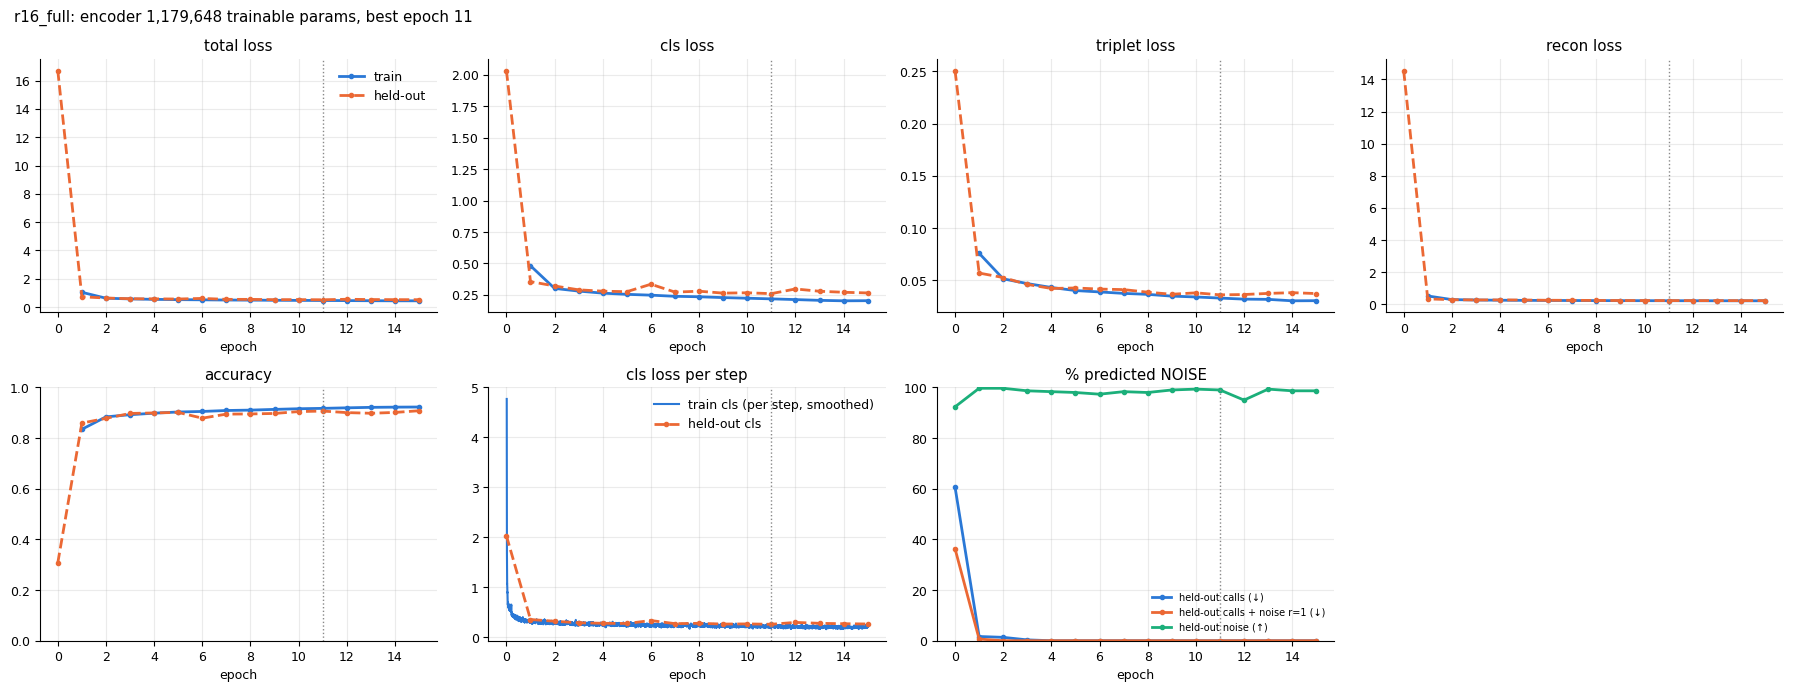

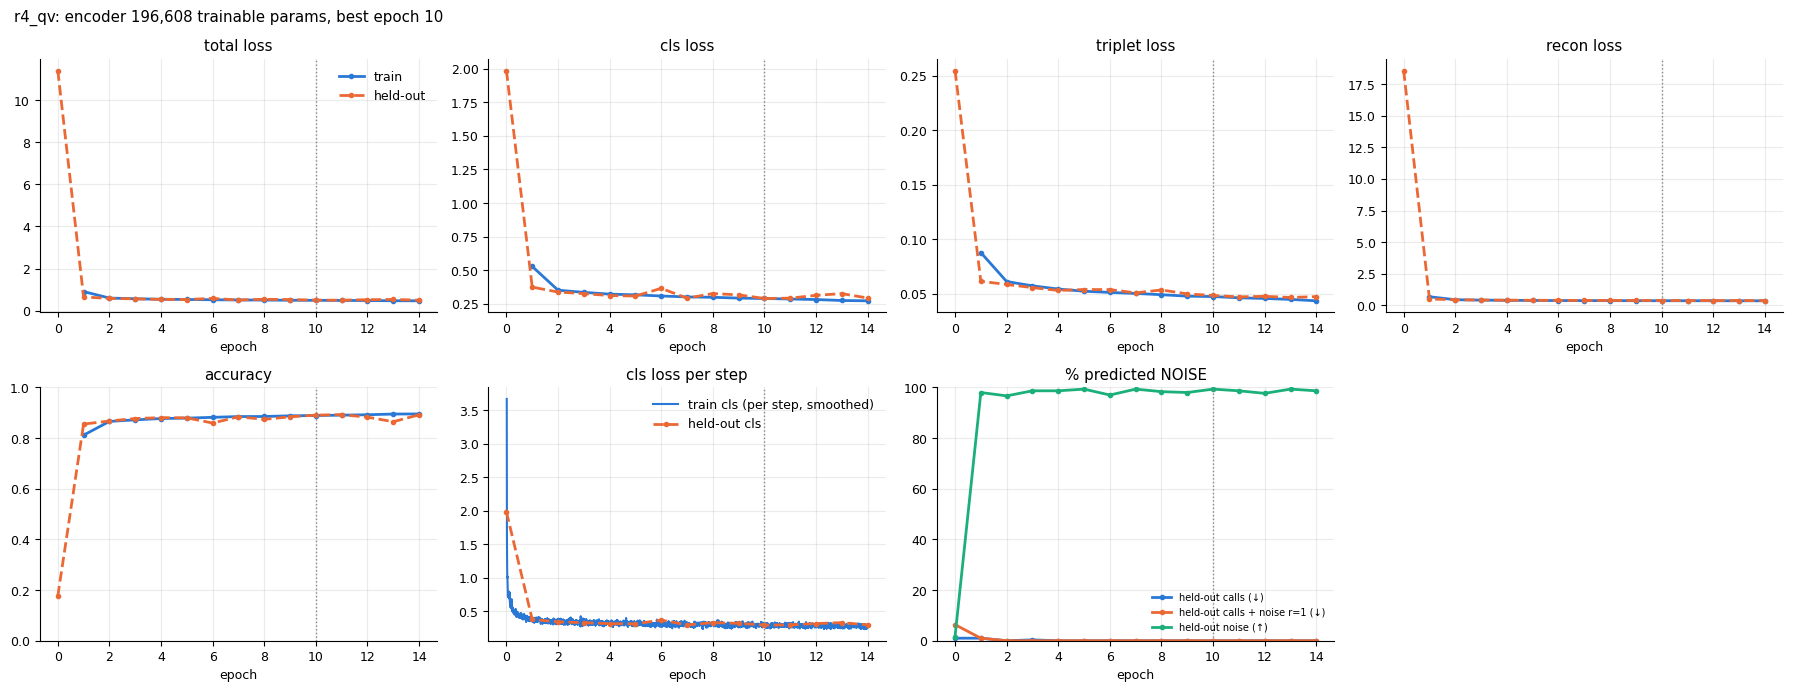

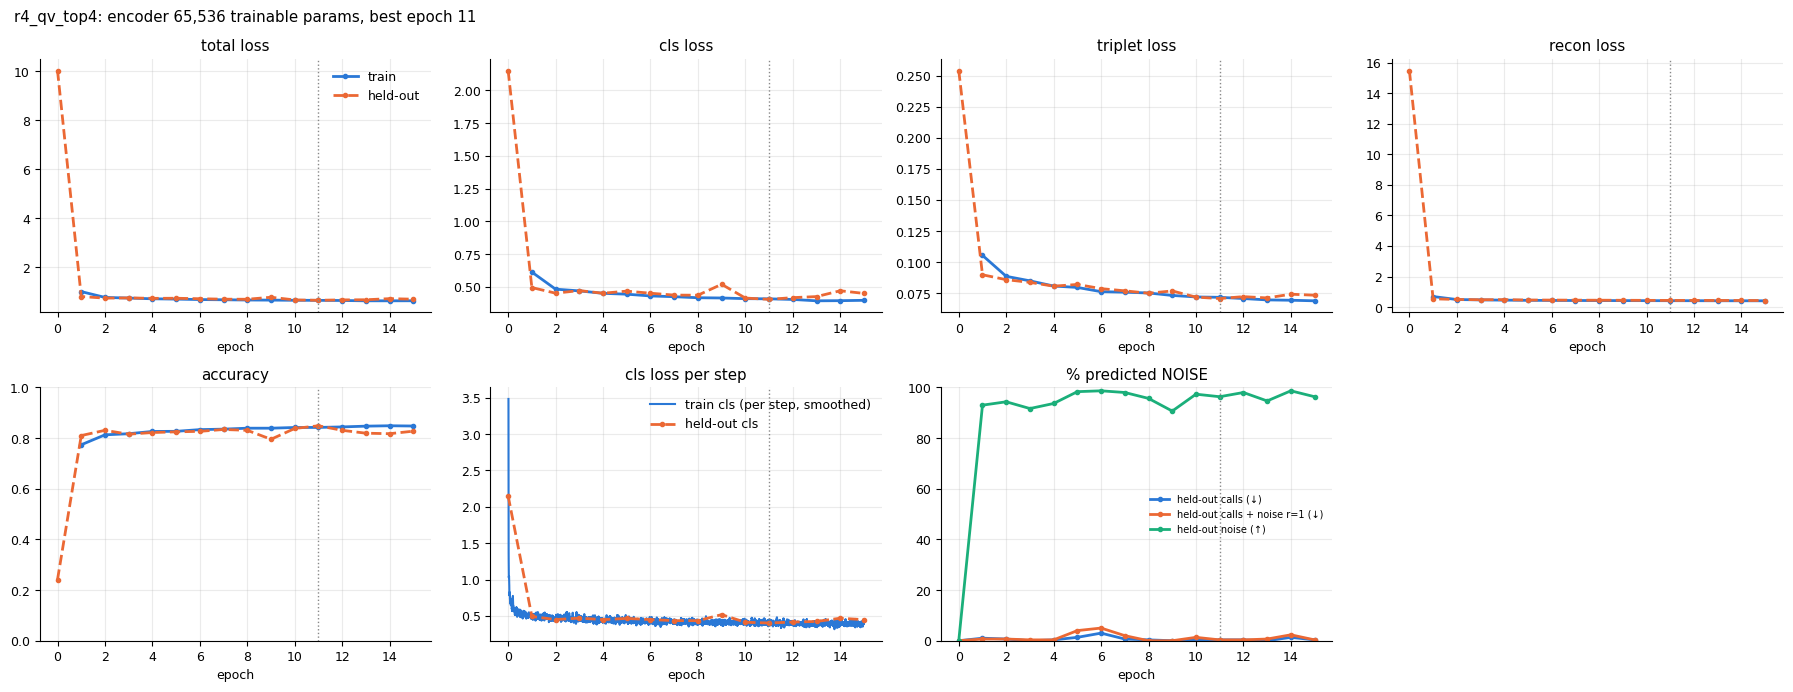

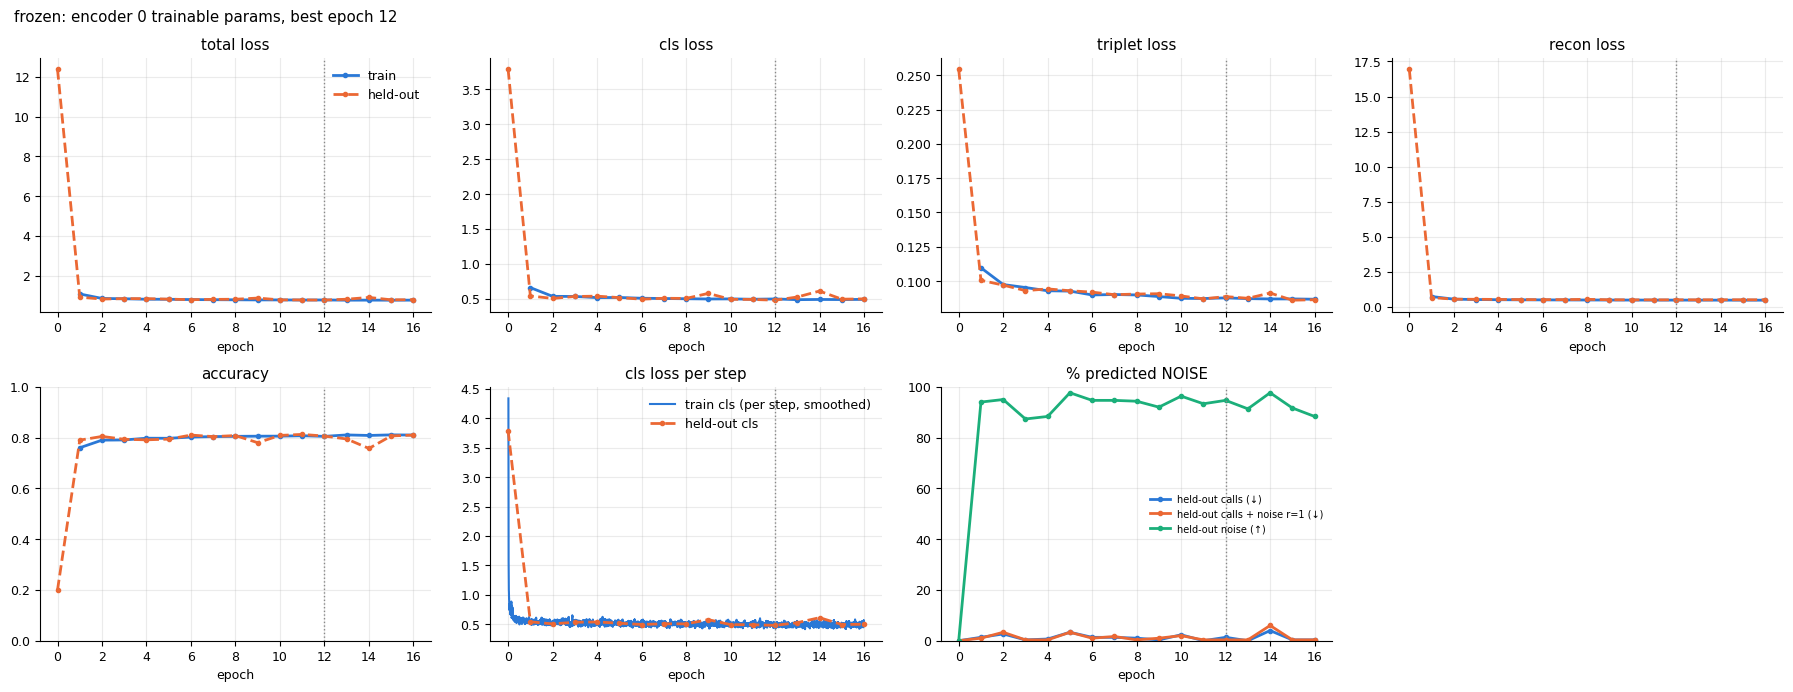

In [10]:
# reload every finished run from Drive (also works in a fresh session after the training cell)
histories = {}
for name in RUNS:
    p = f"{OUT_ROOT}/wdp-embeddinggemma2-lowcap_{name}/history.json"
    if os.path.exists(p):
        with open(p) as f:
            histories[name] = json.load(f)
print("runs found:", list(histories))

TRAIN_C, VAL_C = '#2a78d6', '#eb6834'                       # fixed: train = blue, held-out = orange
PROBE_C = {'val_calls': '#2a78d6', 'val_calls_r1': '#eb6834', 'val_noise': '#1baf7a', 'aggression': '#6250d6'}
PROBE_LABEL = {'val_calls': 'held-out calls (↓)', 'val_calls_r1': 'held-out calls + noise r=1 (↓)',
               'val_noise': 'held-out noise (↑)', 'aggression': 'aggression (↓)'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.25, 'lines.linewidth': 2, 'font.size': 9})

for name, h in histories.items():
    ep = pd.DataFrame(h['epochs'])
    st = pd.DataFrame(h['steps'])
    fig, axes = plt.subplots(2, 4, figsize=(18, 7))
    axes[1, 3].axis('off')
    axes = axes.ravel()[:7]
    for ax, k in zip(axes[:4], LOSSES):
        ax.plot(ep.epoch, ep[f'train_{k}'], color=TRAIN_C, marker='o', ms=3, label='train')
        ax.plot(ep.epoch, ep[f'val_{k}'], color=VAL_C, marker='o', ms=3, ls='--', label='held-out')
        ax.set_title(f'{k} loss'); ax.set_xlabel('epoch')
    axes[0].legend(frameon=False)
    ax = axes[4]
    ax.plot(ep.epoch, ep.train_acc, color=TRAIN_C, marker='o', ms=3, label='train')
    ax.plot(ep.epoch, ep.val_acc, color=VAL_C, marker='o', ms=3, ls='--', label='held-out')
    ax.set_title('accuracy'); ax.set_ylim(0, 1); ax.set_xlabel('epoch')
    ax = axes[5]
    if len(st):                                              # step i of epoch e sits inside (e-1, e]
        x = (st.groupby('epoch').cumcount() + 1) / st.groupby('epoch').epoch.transform('size') + st.epoch - 1
        k = min(20, len(st))
        ax.plot(x.values[k - 1:], np.convolve(st.cls.values, np.ones(k) / k, mode='valid'), color=TRAIN_C, lw=1.5,
                label='train cls (per step, smoothed)')
    ax.plot(ep.epoch, ep.val_cls, color=VAL_C, marker='o', ms=3, ls='--', label='held-out cls')
    ax.set_title('cls loss per step'); ax.set_xlabel('epoch'); ax.legend(frameon=False, loc='upper right')
    ax = axes[6]
    for p in PROBE_C:
        if f'noise%_{p}' in ep:
            ax.plot(ep.epoch, ep[f'noise%_{p}'], color=PROBE_C[p], marker='o', ms=3, label=PROBE_LABEL[p])
    ax.set_title('% predicted NOISE'); ax.set_ylim(0, 100); ax.set_xlabel('epoch'); ax.legend(frameon=False, fontsize=7)
    for ax in axes:
        ax.axvline(h['best_epoch'], color='#888888', lw=1, ls=':')
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    tp = h['trainable_params']
    fig.suptitle(f"{name}: encoder {tp['encoder']:,} trainable params, best epoch {h['best_epoch']}", x=0.01, ha='left')
    fig.tight_layout()
    fig.savefig(f"{OUT_ROOT}/wdp-embeddinggemma2-lowcap_{name}/curves.png", dpi=120)
    plt.show()

## Runs side by side
Same metric, one line per run (colors follow the run, not its rank). Left to right: held-out classification loss, generalization gap (held-out minus train cls loss; growing = overfitting), held-out calls + background at r = 1, aggression NOISE %.

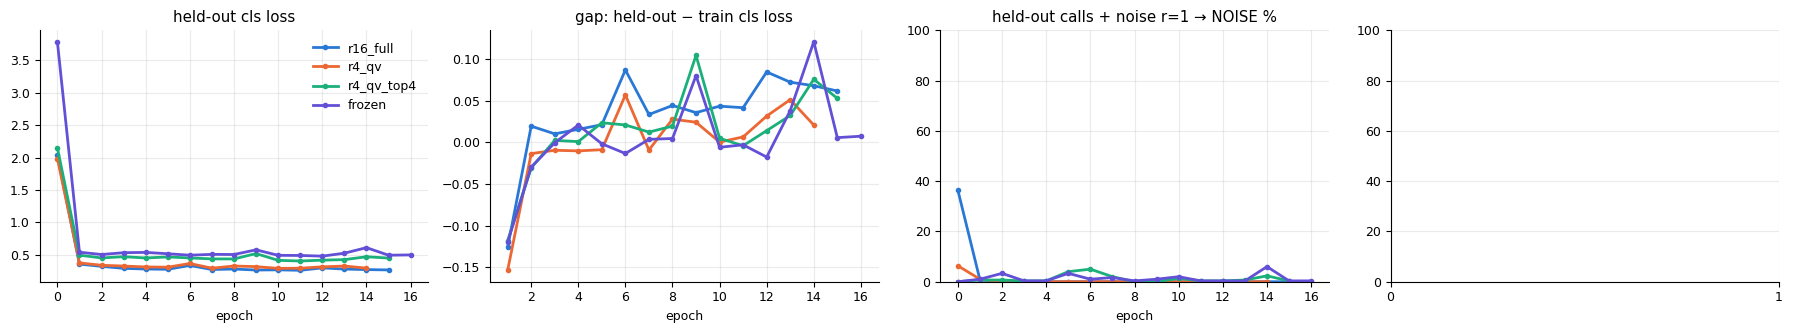

,encoder params,best epoch,epochs run,train cls,held-out cls,gap,held-out acc,calls→NOISE %,calls+r1→NOISE %,noise→NOISE %,aggression→NOISE %,calls+r4→NOISE %
run,,,,,,,,,,,,
r16_full,1179648,11,15,0.219,0.260,0.041,0.907,0.000,0.000,99.000,NaN,0.0
r4_qv,196608,10,14,0.290,0.290,0.000,0.891,0.000,0.000,99.333,NaN,0.0
r4_qv_top4,65536,11,15,0.408,0.404,-0.004,0.849,0.333,0.333,96.333,NaN,0.0
frozen,0,12,16,0.497,0.479,-0.018,0.806,1.333,0.333,94.667,NaN,0.0


In [11]:
RUN_C = dict(zip(RUNS, ['#2a78d6', '#eb6834', '#1baf7a', '#6250d6', '#e87ba4', '#008300']))
panels = [('val_cls', 'held-out cls loss'), ('gap', 'gap: held-out − train cls loss'),
          ('noise%_val_calls_r1', 'held-out calls + noise r=1 → NOISE %'), ('noise%_aggression', 'aggression → NOISE %')]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.4))
for name, h in histories.items():
    ep = pd.DataFrame(h['epochs'])
    ep['gap'] = ep.val_cls - ep.train_cls
    for ax, (k, title) in zip(axes, panels):
        if k in ep:
            ax.plot(ep.epoch, ep[k], color=RUN_C[name], marker='o', ms=3, label=name)
            ax.set_title(title); ax.set_xlabel('epoch')
axes[0].legend(frameon=False)
for ax in axes[2:]:
    ax.set_ylim(0, 100)
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.tight_layout()
fig.savefig(f"{OUT_ROOT}/wdp-embeddinggemma2-lowcap_comparison.png", dpi=120)
plt.show()

rows = []
for name, h in histories.items():
    ep = pd.DataFrame(h['epochs']).set_index('epoch')
    b = ep.loc[h['best_epoch']]
    rows.append({'run': name, 'encoder params': h['trainable_params']['encoder'], 'best epoch': h['best_epoch'],
                 'epochs run': int(ep.index.max()), 'train cls': b.train_cls, 'held-out cls': b.val_cls,
                 'gap': b.val_cls - b.train_cls, 'held-out acc': b.val_acc,
                 'calls→NOISE %': b['noise%_val_calls'], 'calls+r1→NOISE %': b['noise%_val_calls_r1'],
                 'noise→NOISE %': b['noise%_val_noise'], 'aggression→NOISE %': b.get('noise%_aggression', np.nan),
                 'calls+r4→NOISE %': h['r_sweep']['4']})
summary = pd.DataFrame(rows).set_index('run')
summary.to_csv(f"{OUT_ROOT}/wdp-embeddinggemma2-lowcap_summary.csv")
summary.round(3)

## Reading the result, then testing in dolphin_msa
* **Overfitting:** in `r16_full`, held-out cls loss bottoms out early and climbs while train keeps falling, or aggression NOISE % rises over epochs. If the smaller runs keep a smaller gap and a lower aggression NOISE % at similar held-out accuracy, capacity was the problem.
* **Not capacity:** all runs (even `frozen`) put most aggression windows into NOISE. Then the cause is the NOISE data (one noise recording), and the fix is noise from many recordings.
* Held-out L2 call types are pseudo-labels from an older model, so held-out accuracy on them is an upper bound, not ground truth.

To run a checkpoint through the aggression pipeline: unzip `wdp-embeddinggemma2-lowcap_<run>.zip` into `dolphin_msa/model/`, add `embeddinggemma2_lowcap_<run>` (and `_nonoise` with `mask_noise: true`) to `config.yaml`, then `processing.py distance … --model …` and `evaluate.py`.